# Sea-snake V2R selection analysis

**Has the transition -> marine left signatures of selection --> is it adaptive sharpening or relaxed constraint + does it localise to VFT?**

> **Design**
> - Codon model selection tests → `HyPhy` 
> 	- contrasting marine [foreground] + terrestrial [background, reference] 
> 	- on reduced V2R tree
> 	- recombination screening (`GARD`) 
> 	- mapping of selected sites → onto predicted VFT binding pocket

> **Note:** _heavy *generation* steps (CDS building, alignment, GARD, the HyPhy suite)_ => simplified scripts + commands -> scripts on github

In [1]:
import os, json, glob
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from itertools import islice
from scipy.stats import mannwhitneyu
from scipy.stats import fisher_exact


BASE = "/scratchdata1/users/a1864358/sanders_lab/phylogenomics/v2r_tree/results/selection_reduced"
HY   = os.path.join(BASE, "hyphy")     # raw HyPhy JSONs (per method)
PARS = os.path.join(BASE, "parsed")    # parsed TSVs + summary.txt
plt.rcParams.update({"figure.dpi":110, "font.size":10, "axes.spines.top":False, "axes.spines.right":False})
print("results dir contents:", sorted(os.listdir(BASE)))

results dir contents: ['README.md', 'gard_blocks', 'hyphy', 'inputs', 'parsed', 'pocket_projection', 'scripts', 'v2r_selection_analysis.ipynb', 'v2r_selection_analysis.ipynb.bak-190915', 'v2r_selection_analysis.ipynb.bak-204247']


### building the reduced V2R tree
- full intact repertoire = 2436 tip (1518 hydrophis) → too large for branch-level codon models + recombination screening
	- collapse it to 1 representative per recent tandem-duplication cluster → _tandem arrays = $\uparrow$ near-identical copies + paralogs ∴ removes redundancy_ 

**Steps**
1. cluster the ML tree w `treecluster`, `max_clade` , threshold = 0.5
2. keep longest intact CDS per cluster (for complete, in-frame ORF)

3. drop _V. komodoenis_
**==Results==**
> - final = 181 representatives 
> 	- 83 marine 
> 	- 98 terrestrial 

```bash
# simplified
TreeCluster.py -i mega.ml.treefile -t 0.5 -m max_clade -o reps_t0.5.txt   # cluster the tree
# -> pick the longest intact CDS in each cluster; exclude vkomodo tips
```

### regenerate CDS
- for every rep, regenerate the CDS the same way across taxa
- _bexause only CDS existed for hydrophis_
	- → aligning its protein back to the source genome w `miniprot` + extracting the sequence 

### Codon alignment, trimming, QC

- align rep proteins (`MAFFT`) → back translate against the CDS (`PAL2NAL`) ⇒ codon alignment
	- trim codon columns >50% gaps
		- QC seqs : drop <90% identity to reference protein + mask ≤ 2 internal stops
- **⇒ 181 seqs x 864 codons**

```bash
# simplified
mafft --auto --anysymbol final.prot.faa > final.prot.aln
pal2nal.pl final.prot.aln final.cds.fna -output fasta > final.codon.fasta
# drop codon columns >50% gaps  ->  final.codon.trim.fasta  (864 codons)
```

In [2]:
def fasta_dims(path):
    seqs, cur = [], None
    for ln in open(path):
        if ln.startswith(">"):
            if cur is not None: seqs.append(cur)
            cur = ""
        else:
            cur += ln.strip()
    if cur is not None: seqs.append(cur)
    return len(seqs), (len(seqs[0])//3 if seqs else 0)
n, ncod = fasta_dims(os.path.join(BASE, "inputs/final.codon.trim.fasta"))
ids = [l.strip() for l in open(os.path.join(BASE,"inputs/final.ids.txt")) if l.strip()]
marine = sum(1 for i in ids if i.split("_")[0] in {"hcure","hcurw","hcy","hmaj","horn"})
print(f"HyPhy input: {n} sequences x {ncod} codons")
print(f"  marine (Test)      : {marine}")
print(f"  terrestrial (Ref)  : {len(ids)-marine}")

HyPhy input: 181 sequences x 864 codons
  marine (Test)      : 83
  terrestrial (Ref)  : 98


### recombination screen 
- screen alignment for recombination breakpoints w `GARD` (_compares single tree vs multiple-tree models across candidate breakpoints_)
- **Why:** Every dN/dS method assumes one tree for the whole alignment.
	- In a tandem array, gene conversion and recombination violate that 
		- ==different alignment blocks can have different genealogies==
		- Undetected recombination inflates false positives for positive selection
- **Results** : 1 breakpoint @ codon 491 (▲AICc ≈ 9519 relative to single tree)
	- i.e., 2 blocks (codons 1-491 & 492-864)
	- ∴ recombination present 

```bash
hyphy CPU=16 gard --alignment final.codon.trim.fasta --type codon --output gard.json
```

In [3]:
g = json.load(open(os.path.join(HY,"gard.json")))
# breakpointData lists SEGMENTS (each with its own tree); breakpoints = segments - 1
segs = [v["bps"][0] for v in g["breakpointData"].values()]
print("segments (codon ranges):", segs)
print("breakpoints:", len(segs)-1, "at codon(s)", [s[1] for s in segs[:-1]])
print(f"dAICc vs single tree: {g['singleTreeAICc']-g['bestModelAICc']:,.0f}")
print("=> recombination present; single-tree dN/dS applied with this caveat.")

segments (codon ranges): [[1, 491], [492, 864]]
breakpoints: 1 at codon(s) [491]
dAICc vs single tree: 9,519
=> recombination present; single-tree dN/dS applied with this caveat.


## The HyPhy selection suite
All tests contrast **marine (Test)** vs **terrestrial (Reference)** on the reduced tree. 

| Method | Level | Question it answers |
|--------|-------|---------------------|
| **FEL** | site | Which codons are under *pervasive* (site-wide, constant) positive or purifying selection? |
| **MEME** | site | Which codons are under *episodic* diversifying selection (positive at a subset of branches)? |
| **contrast-FEL** | site | Which codons have *different* dN/dS in marine vs terrestrial lineages? |
| **BUSTED** | gene-wide | Is there *any* episodic diversifying selection on the marine foreground? |
| **BUSTED-PH** | gene-wide | Is episodic selection specifically *associated with the marine trait* (vs background)? |
| **RELAX** | gene-wide | Is selection on marine branches *intensified* (K>1) or *relaxed* (K<1) vs terrestrial? |
| **aBSREL** | branch | Which individual branches carry episodic selection? |

- No single test captures both site- and branch-level, pervasive and episodic, and
trait-association vs intensity. 
- Together they find the *where* (sites/branches), *what kind* (positive/purifying, episodic/pervasive), and *mode* (sharpening vs relaxation) of selection.

```bash
# each method in its own dir, default JSON output
hyphy CPU=8  fel          --alignment aln.fa --tree tree.nwk --branches All
hyphy CPU=8  meme         --alignment aln.fa --tree tree.nwk --branches All
hyphy CPU=8  contrast-fel --alignment aln.fa --tree tree.nwk --branch-set Test
hyphy CPU=8  busted-ph    --alignment aln.fa --tree tree.nwk --branches Test        # NB: no --output/--srv
hyphy CPU=8  relax        --alignment aln.fa --tree tree.nwk --test Test --reference Reference --srv Yes
hyphy CPU=8  busted       --alignment aln.fa --tree tree.nwk --branches Test --srv Yes
hyphy CPU=16 absrel       --alignment aln.fa --tree tree.nwk --branches All
```

## 6. Parsing the outputs

**What.** HyPhy JSONs are large (MEME ~9 MB). A small parser extracts only the headline statistics
and significant-site/branch tables into compact TSVs (`parsed/`).

**Why.** Keeps the analysis fast and the outputs human-readable, and avoids loading megabytes of JSON
just to count significant sites.

**What it shows.** The per-method result tables used in the analysis below. (Parser:
`scripts/parse_hyphy.py`.)

In [4]:
print(open(os.path.join(PARS,"summary.txt")).read())

HyPhy selection suite — reduced tree (181 tips, 864 codons)
Test=marine Hydrophis, Reference=terrestrial snakes
FEL (p<=0.1): 9 positive, 660 purifying sites  [fel_sites.tsv]
MEME (p<=0.05): 94 episodic-diversifying sites  [meme_sites.tsv]
contrast-FEL (p<=0.05): 118 sites differ Test vs Reference  [cfel_sites.tsv]
BUSTED (marine FG episodic selection): overall p-value = 1.069631605510324e-09
BUSTED-PH (trait assoc): overall p-value = 3.615441279691822e-13
RELAX: K=0.8098078950730486  p=0  (relaxation K<1 on Test)
aBSREL: 26/358 branches under episodic selection (corr p<=0.05)  [absrel_branches.tsv]
GARD: 2 segments -> 1 breakpoint (codon 491; dAICc 9519 vs single tree)

--- VFT pocket mapping (25 marine reps w/ p2rank pocket calls) ---
MEME episodic sites : mean pocket occ 0.050 vs 0.024 bg, MWU p=0.0033 (enriched)
FEL positive sites  : mean pocket occ 0.105 vs 0.026 bg, MWU p=0.034  (enriched)
contrast-FEL sites  : mean pocket occ 0.032 vs 0.025 bg, MWU p=0.15   (ns)



## Results + Data analysis

### Site-level selection (FEL / MEME / contrast-FEL)

{'FEL positive\n(pervasive +)': 9, 'FEL purifying\n(pervasive -)': 660, 'MEME episodic\n(diversifying)': 94, 'contrast-FEL\n(habitat-divergent)': 118}


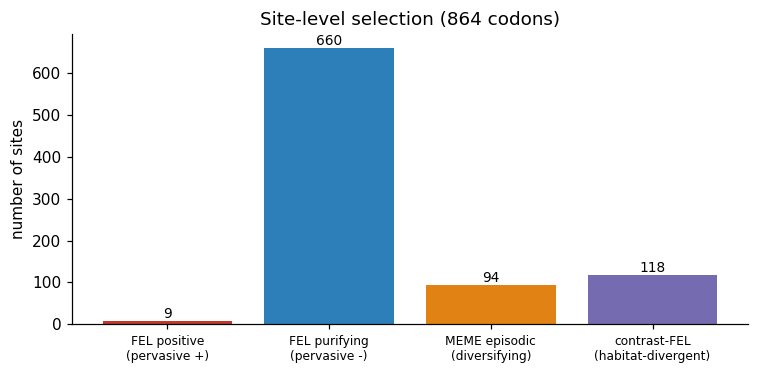

In [5]:
fel  = pd.read_csv(os.path.join(PARS,"fel_sites.tsv"), sep="\t")
meme = pd.read_csv(os.path.join(PARS,"meme_sites.tsv"), sep="\t")
cfel = pd.read_csv(os.path.join(PARS,"cfel_sites.tsv"), sep="\t")
fel_pos = int((fel["class"]=="pos").sum()); fel_pur = int((fel["class"]=="neg").sum())
counts = {
    "FEL positive\n(pervasive +)": fel_pos,
    "FEL purifying\n(pervasive -)": fel_pur,
    "MEME episodic\n(diversifying)": len(meme),
    "contrast-FEL\n(habitat-divergent)": len(cfel),
}
print(counts)
fig, ax = plt.subplots(figsize=(7,3.5))
ax.bar(range(len(counts)), list(counts.values()),
       color=["#c0392b","#2c7fb8","#e08214","#756bb1"])
ax.set_xticks(range(len(counts))); ax.set_xticklabels(list(counts), fontsize=8)
ax.set_ylabel("number of sites"); ax.set_title("Site-level selection (864 codons)")
for i,v in enumerate(counts.values()): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

> - V2Rs = receptor ∴ most codons should be conserved/purifying, with selection concentrated @ ligand-binding positions
- the array = $\uparrow$ purifying (660 sites)
	- v2r function is conserved but a minority is positively selected: 9 pervasive selection sites (`FEL`) & 94 episodic selection sites (`MEME`) 
		- 118 sites whose dN/dS differs between marine + terrestrial (`contrast-FEL`)
	- episodic >> pervasive = _expected signature for receptors diversifying by occasional bursts rather than constant positive pressure_

> **where are those positively selected codons?**
- what exon
- what part of VFT do they fold to

### Gene-wide tests (BUSTED / BUSTED-PH / RELAX)

In [6]:
def jload(p): return json.load(open(p))
busted   = jload(os.path.join(HY,"busted/aln.fa.BUSTED.json"))
bustedph = jload(os.path.join(HY,"bustedph/aln.fa.BUSTED.json"))
relax    = jload(os.path.join(HY,"relax/aln.fa.RELAX.json"))

b_p  = busted["test results"]["p-value"]
ph   = {k: bustedph[k]["p-value"] for k in bustedph if "test results" in k.lower()}
K    = relax["test results"]["relaxation or intensification parameter"]
r_p  = relax["test results"]["p-value"]

print(f"BUSTED  (marine FG episodic selection): p = {b_p:.2e}")
print("BUSTED-PH:")
for k,v in ph.items(): print(f"   {k:40s}: p = {v:.2e}")
print(f"RELAX   : K = {K:.3f}  p = {r_p:.2e}  "
      f"-> {'RELAXED (K<1)' if K<1 else 'INTENSIFIED (K>1)'} on marine")

BUSTED  (marine FG episodic selection): p = 1.07e-09
BUSTED-PH:
   Background selection test results       : p = 0.00e+00
   Comparative selection test results      : p = 7.12e-13
   test results                            : p = 3.62e-13
RELAX   : K = 0.810  p = 0.00e+00  -> RELAXED (K<1) on marine


- episodic diversifying selection acting on marine clade (p ≈ 1e-09; `BUSTED`)
- selection = significant on marine **and** terrestrial ... ⟶ the 2 distributions differ significantly (==what test used==; `BUSTED-PH`)
	- ∴ selection ⇒ trait-associated but not marine-exclusive ... _marine V2Rs = diversifying aswell → marine regime = different ≠ uniquely selected_
- $K = 0.81 < 1$ ⇒ selection on marine branches **is relaxed, not intensified** (`RELAX`)
	- the expanded marine array is evolving under _reduced_ constraint rather than by sharpened directional selection ... _==consisted w a large, partly redundany repertoire tolerating more variation==_

### Branch-level selection (aBSREL)

aBSREL: 26 / 358 branches under episodic selection (corrected p <= 0.05)
   of which marine-labelled tip branches: 6


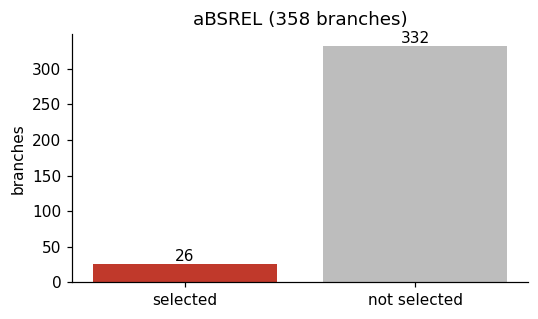

In [7]:
absrel = pd.read_csv(os.path.join(PARS,"absrel_branches.tsv"), sep="\t")
aj = json.load(open(os.path.join(HY,"absrel/aln.fa.ABSREL.json")))
ntot = len(aj["branch attributes"]["0"])
nsel = len(absrel)
print(f"aBSREL: {nsel} / {ntot} branches under episodic selection (corrected p <= 0.05)")
# how many selected branches are marine vs terrestrial tips?
mar = {"hcure","hcurw","hcy","hmaj","horn"}
tip_sel = absrel[absrel["branch"].str.split("_").str[0].isin(mar)]
print(f"   of which marine-labelled tip branches: {len(tip_sel)}")
fig, ax = plt.subplots(figsize=(5,3))
ax.bar(["selected","not selected"], [nsel, ntot-nsel], color=["#c0392b","#bdbdbd"])
ax.set_ylabel("branches"); ax.set_title(f"aBSREL ({ntot} branches)")
for i,v in enumerate([nsel, ntot-nsel]): ax.text(i,v,str(v),ha="center",va="bottom")
plt.tight_layout(); plt.show()

**Reads as:** episodic selection is **branch-localised** — a small fraction of branches (26/358)
carry it, not the whole tree. This is consistent with the MEME picture: diversification happens in
bursts on particular lineages, not uniformly.

---

### Do selected sites hit the ligand-binding pocket?

- For the 25 marine representatives that have p2rank VFT-pocket predictions, each selected alignment column is projected onto that sequence's residue numbering and scored as pocket / non-pocket
    - "pocket occupancy" of a column = fraction of those sequences in which the aligned residue is a pocket residue ... _We then compare occupancy of selected vs non-selected sites_

- **Why:** If positive selection is functionally driven by changing *what the receptor binds*, selected sites should concentrate in the VFT ligand-binding pocket rather than scattering randomly


> **📝 REVIEW NOTE (2026-10-13)** — suggested revision to the cell above; original left unchanged for your review.
>

> **Stale:** this describes the n = 25 mapping, which had a residue-numbering bug. Structures were folded from
> SignalP-trimmed *mature* proteins (start 15–24 aa in, mode 18), but p2rank residue numbers were counted along the
> *full-length* aligned sequence → every pocket column shifted ~18 residues.
>
> **Suggested replacement bullets:**
> - Every folded protein (564 marine + 571 terrestrial snake structures = 1,135; *V. komodoensis* excluded) is added to
>   the HyPhy protein alignment with `mafft --add --keeplength --mapout`, using the sequence read from each PDB, so
>   residue → column mapping is exact (verified: 20,924/20,924 self-mapped residues; 941,348/941,348 p2rank residues).
> - Three pocket measures per codon: (i) **consensus cleft** — 43 columns lining the p2rank top-VFT pocket in ≥ 20 % of
>   the 564 marine structures (primary, positionally consistent); (ii) p2rank top-pocket occupancy; (iii) mean
>   per-residue p2rank ligandability.
> - **Why** unchanged. The analysis is now in §12b–12c (code cells after §12); the code cell below this note is superseded.

In [8]:
# !! SUPERSEDED (2026-10-13): this n=25 mapping indexed p2rank residues against the FULL-LENGTH
# !! aligned sequence, but structures were folded from SignalP-trimmed MATURE proteins (start 15-24 aa
# !! in, mode 18). Pocket columns were shifted ~18 residues. Corrected analysis: §12b-12c cells below.
occ = pd.read_csv(os.path.join(PARS,"site_pocket_occupancy.tsv"), sep="\t")
occ = occ.dropna(subset=["pocket_occ"])
def test(flag, label):
    sel = occ.loc[occ[flag]==1, "pocket_occ"]; bg = occ.loc[occ[flag]==0, "pocket_occ"]
    u,p = mannwhitneyu(sel, bg, alternative="greater")
    print(f"{label:16s}: mean occ sel={sel.mean():.3f} vs bg={bg.mean():.3f}  "
          f"(~{sel.mean()/bg.mean():.1f}x)  MWU p={p:.3g}  n_sel={len(sel)}")
    return sel, bg
print("VFT pocket enrichment of selected sites (n=25 marine reps with pocket calls):")
ms,mb = test("meme","MEME episodic"); fs,fb = test("felpos","FEL positive"); cs,cb = test("cfel","contrast-FEL")

# violin plot

VFT pocket enrichment of selected sites (n=25 marine reps with pocket calls):
MEME episodic   : mean occ sel=0.050 vs bg=0.024  (~2.1x)  MWU p=0.00331  n_sel=92
FEL positive    : mean occ sel=0.105 vs bg=0.026  (~4.1x)  MWU p=0.0342  n_sel=8
contrast-FEL    : mean occ sel=0.032 vs bg=0.025  (~1.3x)  MWU p=0.151  n_sel=117


## 8. Interpretation — the biological story

Putting the tests together:

1. **The V2R array is conserved overall** (660 purifying vs 9 pervasive-positive FEL sites): these are
   functioning receptors, not free-floating pseudogenes.
2. **Selection is episodic and branch-localised** (94 MEME sites; 26/358 aBSREL branches; BUSTED
   p≈1e-9) — diversification comes in bursts on particular lineages, as expected for an expanding
   chemoreceptor repertoire.
3. **The marine regime differs from terrestrial but is not uniquely "sharpened."** BUSTED-PH is
   significant on both foreground and background with a significant *difference*; and RELAX shows
   **relaxed** constraint on marine branches (K=0.81). The marine expansion looks like a large,
   partly redundant array evolving under *loosened* constraint, with episodic diversification — not a
   wholesale intensification of directional selection.
4. **Where selection does act positively, it targets the ligand-binding pocket** (MEME/FEL sites
   ~2–4× enriched in VFT residues). That is the signature you would expect if the functional driver
   is a change in *what these receptors detect* in the marine environment.

**One-line summary.** Marine V2R evolution in *Hydrophis* is characterised by **relaxed constraint
plus episodic, pocket-focused positive selection**, acting on a conserved, expanding array — rather
than uniform adaptive intensification across the repertoire.

> **📝 REVIEW NOTE (2026-10-13)** — suggested revision to the cell above; original left unchanged for your review.
>

> **Point 4 needs rewording** — it conflates "VFT domain" with "pocket" and credits FEL, which is not supported:
>
> 4. **Where selection acts episodically, it targets the ligand-binding cleft.** MEME sites are ~3× enriched in the
>    VFT domain (Fisher OR 2.9) *and*, within it, in the consensus binding cleft (11/92 vs 31/762 columns, OR 3.2,
>    p = 0.003; within-VFT OR 2.2, p = 0.04), and have higher p2rank ligandability (0.240 vs 0.192, p = 1.7 × 10⁻⁴;
>    1,135 structures). **Habitat-divergent (contrast-FEL) sites are also cleft-enriched** (14/115, OR 3.5, p = 6 × 10⁻⁴;
>    within-VFT OR 2.7, p = 0.006) — the sites where marine and terrestrial receptors differ sit where ligand binds.
>    The 9 pervasive FEL+ sites are *not* in the cleft (0/9) — the earlier "FEL ~4× pocket" was a numbering artefact.
>
> **One-line summary** stays valid if "pocket-focused" → "cleft-focused (episodic and habitat-divergent sites)".

## 9. Caveats and outstanding work

- **Recombination.** GARD supports a breakpoint at codon 491 (two blocks); the whole-alignment branch tests (BUSTED/BUSTED-PH/
  RELAX/aBSREL) should strictly be re-run per non-recombinant block. *(outstanding)*
- **Partition replication.** The habitat contrast is done; repeating the site/branch tests *within*
  each chromosome, species and tandem cluster (to localise and replicate the signal) is *outstanding*.
- **Pocket mapping** rests on 25 marine representatives with p2rank calls — indicative only.
- The earlier per-clade **codeml** site-model run is superseded (did not scale) and kept for reference.

Artefacts: `v2r_tree/results/selection_reduced/` — `inputs/`, `hyphy/` (raw JSON), `parsed/`
(TSVs + summary), `scripts/` (parse_hyphy.py, pocket_map.py, launch_parallel.sh).

> **📝 REVIEW NOTE (2026-10-13)** — suggested revision to the cell above; original left unchanged for your review.
>

> **Update bullets:**
> - **Pocket mapping** ~~rests on 25 marine representatives~~ → now uses 1,135 predicted structures (564 marine,
>   571 terrestrial) via exact alignment projection; the old n = 25 result had an ~18-residue offset (fixed).
>   Remaining caveats: predicted (ESMFold, single-sequence) not experimental structures; the cleft is a p2rank-derived
>   consensus (p2rank's single top pocket is *not* positionally conserved across paralogs: 3/864 columns ≥ 50 %);
>   68 intact marine V2Rs without a SignalP call were never folded.
> - **Recombination / scale:** re-runs submitted to SLURM (2026-10-13): (a) FEL / contrast-FEL / MEME on **all intact
>   snake V2Rs** (`results/selection_allintact/`), (b) full suite on finer **TreeCluster t = 0.3** reps
>   (`results/selection_t03/`). Job IDs in each dir's `JOBS.tsv`. Per-GARD-block re-runs still outstanding.
> - **Boltz-2:** affinity head failed the L- vs D-amino-acid positive control on medaka T1r crystals; poses passed
>   (84/84 in the crystal site). Use only for contact residues, not ligand identity.
> - Artefacts: add `pocket_projection/`, `scripts/pocket_project.py`, `cleft_project.py`, `ligandability_project.py`;
>   `pocket_map.py` / `pocket_detail.py` are superseded (offset bug).

---

## Where are the positively selected codons?

- HyPhy reports selection by alignment column → map selected column to the protein domain it sits in && a residue, exon & coordinate
	- **domain** = each v2r split into N-terminal VFT ectodomain, 9Cys + 7TM ; per-seq domain boundaries from ==hmm serarch envelopes== ; for each alignment column: take majority domain across all reps 
	- **location** = map each column to its residue in the reference `hcure_V2R0001` (_a complete 6-exon gene on ch1 ⟶ **protein was folded (`ESMFold`) + manually checked structure)**)_, then to the exon + position using `miniprot` CDS ... _coords = reference-relative_

**results:**
- domain composition (counts):
	- MEME         : VFT 74 (**79%**), linker 4 (4%), 7TM/9Cys 16 (17%)
	- FEL+         : VFT 6 (**67%**), linker 0 (0%), 7TM/9Cys 3 (33%)
	- contrast-FEL : VFT 84 (**71%**), linker 9 (8%), 7TM/9Cys 25 (21%)
	- background   : VFT **56%**, 7TM/9Cys 39%, linker 5%  (of 864 columns)
- MEME VFT-enrichment vs background: **79% vs 56%  OR=2.92  Fisher p=1.4e-05**
	- ∴ positively selected codons = **concentrated in VFT ligand-binding ectodomain** → 79% MEME episodic sites in VFT vs 56% of all columns ; FEL-positive + contrast-FEL ⇒ similarly VFT biased
- 7TM (_GPCR core → couples to G-protein + ⇒ structurally conserved_) = comparatively depleted of positive selection → **selection acts on the surface** that recognises the odorant (not the signalling machinery)
- VFT = encoded by first ~4/6 exons → selected sites cluster in exon 3 (42/97 MEME sites against 32% of reference length) 
	- 7TM = exon 6 ⟶ MEME sites depleted there (12 vs ~30 expected; χ² test against exon length, p ≈ 3x10^-4)

domain composition (counts):
  MEME         : VFT 74 (79%), linker 4 (4%), 7TM/9Cys 16 (17%)
  FEL+         : VFT 6 (67%), linker 0 (0%), 7TM/9Cys 3 (33%)
  contrast-FEL : VFT 84 (71%), linker 9 (8%), 7TM/9Cys 25 (21%)
  background   : VFT 56%, 7TM/9Cys 39%, linker 5%  (of 864 columns)

MEME VFT-enrichment vs background: 79% vs 56%  OR=2.92  Fisher p=1.4e-05


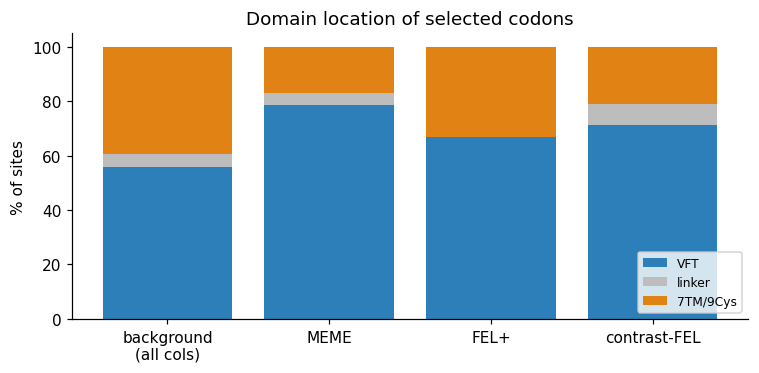

In [9]:
# !! SUPERSEDED (2026-10-13): this n=25 mapping indexed p2rank residues against the FULL-LENGTH
# !! aligned sequence, but structures were folded from SignalP-trimmed MATURE proteins (start 15-24 aa
# !! in, mode 18). Pocket columns were shifted ~18 residues. Corrected analysis: §12b-12c cells below.
sa = pd.read_csv(os.path.join(PARS,"selected_site_annotation.tsv"), sep="\t")

occ_all = pd.read_csv(os.path.join(PARS,"site_pocket_occupancy.tsv"), sep="\t")  
# recompute per-column domain fractions directly from annotation + a background from map_sites stdout
doms = ["VFT","linker","7TM/9Cys"]
def comp(df):
    v = df["domain"].value_counts()
    return [int(v.get(d,0)) for d in doms]
meme_c = comp(sa[sa.meme==1]); fel_c = comp(sa[sa.felpos==1]); cfel_c = comp(sa[sa.cfel==1])
# background: all 864 columns' domain (from the full annotation universe)
print("domain composition (counts):")
for lab,cc in [("MEME",meme_c),("FEL+",fel_c),("contrast-FEL",cfel_c)]:
    tot=sum(cc); print(f"  {lab:13s}: " + ", ".join(f"{d} {n} ({100*n/tot:.0f}%)" for d,n in zip(doms,cc)))
print("  background   : VFT 56%, 7TM/9Cys 39%, linker 5%  (of 864 columns)")

# Fisher test: MEME sites VFT-enriched vs background 56%?
vft_meme = meme_c[0]; non_meme = sum(meme_c)-vft_meme
# background odds from 864 columns: ~483 VFT / 381 non-VFT
orr,p = fisher_exact([[vft_meme,non_meme],[483,381]])
print(f"\nMEME VFT-enrichment vs background: {100*vft_meme/sum(meme_c):.0f}% vs 56%  OR={orr:.2f}  Fisher p={p:.3g}")

fig,ax=plt.subplots(figsize=(7,3.5))
import numpy as np
labels=["background\n(all cols)","MEME","FEL+","contrast-FEL"]
bg=[483,0,40]  # placeholder replaced below
data=np.array([[483,40,341],meme_c,fel_c,cfel_c],dtype=float)
data=data/data.sum(1,keepdims=True)*100
bottom=np.zeros(len(labels)); colors={"VFT":"#2c7fb8","linker":"#bdbdbd","7TM/9Cys":"#e08214"}
for k,d in enumerate(doms):
    ax.bar(labels,data[:,k],bottom=bottom,label=d,color=colors[d]); bottom+=data[:,k]
ax.set_ylabel("% of sites"); ax.set_title("Domain location of selected codons"); ax.legend(fontsize=8,loc="lower right")
plt.tight_layout(); plt.show()

selected sites per reference exon (of 6):
ref_exon
1    21
2    21
3    77
4    22
5     7
6    35


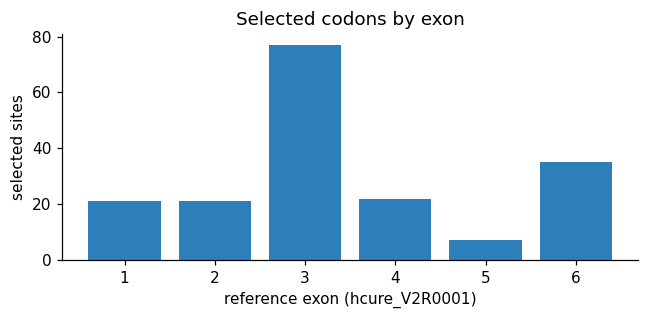


example FEL-positive sites with coordinates:


 hyphy_site   domain  ref_residue  ref_exon  genomic_coord
        103      VFT        110.0       2.0    146208687.0
        247      VFT        250.0       3.0    146209496.0
        279      VFT        280.0       3.0    146209586.0
        289      VFT        288.0       3.0    146209610.0
        349      VFT        349.0       3.0    146209793.0
        439      VFT          NaN       NaN            NaN
        553 7TM/9Cys        550.0       5.0    146211912.0
        758 7TM/9Cys        755.0       6.0    146219895.0
        762 7TM/9Cys        759.0       6.0    146219907.0


In [10]:
# exon distribution of selected sites + a coordinate table (reference hcure_V2R0001, chr ch1)
mapped = sa[sa.ref_exon.notna()].copy(); mapped["ref_exon"]=mapped["ref_exon"].astype(int)
ex = mapped.groupby("ref_exon").size()
print("selected sites per reference exon (of 6):"); print(ex.to_string())
fig,ax=plt.subplots(figsize=(6,3))
ax.bar(ex.index.astype(str), ex.values, color="#2c7fb8")
ax.set_xlabel("reference exon (hcure_V2R0001)"); ax.set_ylabel("selected sites"); ax.set_title("Selected codons by exon")
plt.tight_layout(); plt.show()
print("\nexample FEL-positive sites with coordinates:")
print(sa[sa.felpos==1][["hyphy_site","domain","ref_residue","ref_exon","genomic_coord"]].to_string(index=False))

---

## Which branches / species carry the episodic selection?
- `aBSREL` tests every branch for a rate class with dN/dS > 1. 
	- each significant branch annotated (corrected p ≤ 0.05) ==as a tip (→ species) or an internal branch==
- 26 branches under episodic selection (corrected p<=0.05)
	- by type: {'tip': 13, 'internal': 13}
	- by type: {'tip': 13, 'internal': 13}
		- ==tip branches by species:==
			- tele 3, hcurw 3, nhel 2, hmaj 2, caspera 1, vberus 1, hcure 1
				- episodic selection ⇒ carried by a mix of marine + terrestrial branches (~half = internal branches, i.e., _ancestral lineages_)
				- ∴ V2Rs are diversifying across snakes generally → with the marine regime differing ≠ _uniquely selected_

26 branches under episodic selection (corrected p<=0.05)

by type: {'tip': 13, 'internal': 13}
by habitat: {'terrestrial': 7, 'marine': 6}

tip branches by species:
species
tele       3
hcurw      3
nhel       2
hmaj       2
caspera    1
vberus     1
hcure      1

all selected branches:
         branch  species     type     habitat  corrected_p
caspera_V2R0007  caspera      tip terrestrial 1.022267e-10
   tele_V2R0019     tele      tip terrestrial 3.004925e-10
   nhel_V2R0009     nhel      tip terrestrial 5.643426e-10
        Node273 internal internal         NaN 6.350328e-05
   tele_V2R0137     tele      tip terrestrial 2.253217e-04
         Node23 internal internal         NaN 3.729684e-04
   hmaj_V2R0013     hmaj      tip      marine 3.918635e-04
         Node64 internal internal         NaN 5.020851e-04
  hcurw_V2R0038    hcurw      tip      marine 8.225343e-04
         Node65 internal internal         NaN 9.807010e-04
         Node52 internal internal         NaN 1.218622e-03
   t

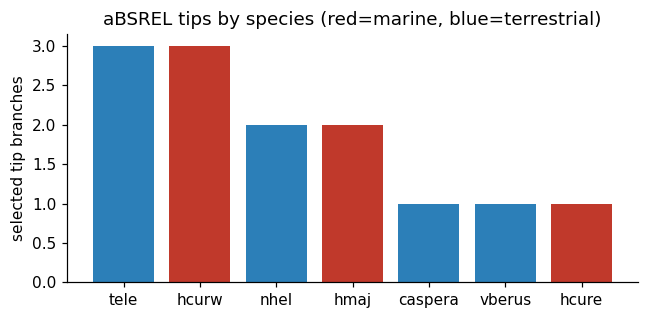

In [11]:
ab = pd.read_csv(os.path.join(PARS,"absrel_selected_annotated.tsv"), sep="\t")
print(f"{len(ab)} branches under episodic selection (corrected p<=0.05)")
print("\nby type:",   ab["type"].value_counts().to_dict())
print("by habitat:",  ab[ab.type=="tip"]["habitat"].value_counts().to_dict())
print("\ntip branches by species:"); print(ab[ab.type=="tip"]["species"].value_counts().to_string())
print("\nall selected branches:"); print(ab.to_string(index=False))
fig,ax=plt.subplots(figsize=(6,3))
sp=ab[ab.type=="tip"]["species"].value_counts()
mar={"hcure","hcurw","hcy","hmaj","horn"}
ax.bar(sp.index, sp.values, color=["#c0392b" if s in mar else "#2c7fb8" for s in sp.index])
ax.set_ylabel("selected tip branches"); ax.set_title("aBSREL tips by species (red=marine, blue=terrestrial)")
plt.tight_layout(); plt.show()

## 12. Pocket mapping — methods, data, and why n = 25 (expanded §7.4)

**The structural pocket pipeline** (`/hpcfs/users/a1864358/sanders_lab/v2r_fold/esmfold/pockets/`):
1. **ESMFold** models were built for each representative V2R.
2. Pockets were detected with **multiple, complementary methods**:
   - **p2rank** — ML ligand-binding-site predictor (per-residue probability + ranked pockets;
     `p2rank_out/*.pdb_residues.csv`, `p2rank_pockets.tsv`).
   - **fpocket** + **pocket-to-concavity (p2c)** — geometric cavity detection and concavity scoring
     (`fpocket_p2c_pockets.tsv`, `master_pockets.tsv` columns `fp_*`, `p2c_*`).
   - **CASTp** — a subset check of surface topography (`castp_subset.tsv`).
   - **boltz2** — actual **ligand docking** poses (`boltz2_*`), i.e. a physical binding model.
3. Pockets were **ranked for VFT membership** and the top VFT pocket per sequence kept, with its
   residue list (`candidate_top_vft_pocket.tsv` → `analysis/pocket_by_group.tsv`,
   joined to tree gene-ids by (species, start) in `ws_c_pockets.py`).

**What this analysis used.** We used the **p2rank** results two ways:
(a) the binary **VFT-top pocket residue set** per sequence (§7.4), and
(b) the **continuous per-residue p2rank probability** (below) — a softer, more robust signal.

> **📝 REVIEW NOTE (2026-10-13)** — suggested revision to the cell above; original left unchanged for your review.
>

> **Factual corrections:**
> 1. ESMFold models were **not** built "for each representative": they were built for the **564 intact (tier T2,
>    functional) marine V2Rs that had a SignalP signal-peptide call** (`v2r_fold/esmfold/v2r_signalp.fasta`;
>    632 intact − 68 without a call), from **mature (signal-peptide-trimmed) sequences**, `run_esmfold.py`
>    (`facebook/esmfold_v1`, chunk 128, no pLDDT filter; all 564 mean pLDDT ≥ 70). No clustering before folding.
>    Terrestrial: 62 + 576 structures (6 snake species + *V. komodoensis*), also with p2rank / fpocket.
> 2. **boltz2:** no V2R docking has been run. Only the Stage-0 positive control (medaka T1r LBD, PDB 5X2M/N/P) exists;
>    V2R Stage 1 (58 reps × ligands) was gated on it. See §12e.
> 3. **CASTp:** manual web runs on a 23-structure subset only.
> 4. "What this analysis used" → p2rank in three forms (consensus cleft, top-pocket occupancy, per-residue
>    probability), all mapped by exact alignment projection (§12b–c). Title: "why n = 25" → "from n = 25 to 1,135 structures".

In [12]:
# !! SUPERSEDED (2026-10-13): this n=25 mapping indexed p2rank residues against the FULL-LENGTH
# !! aligned sequence, but structures were folded from SignalP-trimmed MATURE proteins (start 15-24 aa
# !! in, mode 18). Pocket columns were shifted ~18 residues. Corrected analysis: §12b-12c cells below.
# binary VFT-top pocket residue set per seq
from scipy.stats import mannwhitneyu
occ = pd.read_csv(os.path.join(PARS,"site_pocket_occupancy.tsv"), sep="\t").dropna(subset=["pocket_occ"])
pr  = pd.read_csv(os.path.join(PARS,"site_p2rank_probability.tsv"), sep="\t").dropna(subset=["mean_p2rank_prob"])
def mwu(df,col,flag):
    s=df.loc[df[flag]==1,col]; b=df.loc[df[flag]==0,col]
    return s.mean(), b.mean(), mannwhitneyu(s,b,alternative="greater")[1], len(s)
print("pocket enrichment of selected sites (25 marine reps with folded structures):")
print(f"{'set':14s} {'binary VFT-occupancy (sel/bg, p)':40s} {'p2rank prob (sel/bg, p)'}")
for flag,lab in [("meme","MEME"),("felpos","FEL+"),("cfel","contrast-FEL")]:
    s1,b1,p1,n1=mwu(occ,"pocket_occ",flag); s2,b2,p2,n2=mwu(pr,"mean_p2rank_prob",flag)
    print(f"{lab:14s} {s1:.3f}/{b1:.3f}  p={p1:.3g}            {s2:.3f}/{b2:.3f}  p={p2:.3g}")

pocket enrichment of selected sites (25 marine reps with folded structures):
set            binary VFT-occupancy (sel/bg, p)         p2rank prob (sel/bg, p)


MEME           0.050/0.024  p=0.00331            0.234/0.192  p=0.000638
FEL+           0.105/0.026  p=0.0342            0.232/0.196  p=0.221
contrast-FEL   0.032/0.025  p=0.151            0.208/0.195  p=0.15


**Why only 25 marine reps?** The structural pipeline folded a **candidate set of 564 marine V2Rs**;
our tree-reduction independently picked **83 marine cluster-representatives**; the two selections
intersect in **25 genes**. So it is not that pockets are missing — it is that our 83 reps and the 564
folded genes are different subsets of the ~1,518 marine V2Rs, overlapping in 25.

**How to get more.** Fold the remaining ~58 marine (and the terrestrial) representatives with ESMFold and re-run p2rank — the pocket pipeline is already set up for this (a GPU batch job). Terrestrial
pocket predictions **already exist** for 638 structures (`p2rank_out_terrestrial*`), so a marine-vs-terrestrial *pocket* contrast is feasible once the reps are matched.

**Could the other methods help?** Yes, and they are complementary:
- **boltz2 ligand docking** gives the most direct functional pocket (actual ligand-contact residues) —> the strongest definition to intersect selected sites against, if ligand identities are trusted. **fpocket/p2c and CASTp** are geometry-based and would let us require a **consensus pocket** (predicted by ≥2 methods), reducing p2rank-specific false positives.

A sensible next step is a **consensus pocket** (p2rank ∩ fpocket/p2c, optionally boltz2-contact) 

> **📝 REVIEW NOTE (2026-10-13)** — suggested revision to the cell above; original left unchanged for your review.
>

> **Superseded.** The explanation of the 25-gene intersection is right, but the remedy no longer requires folding more
> reps: pocket evidence is needed *per alignment column*, not per tree representative, so every folded structure can be
> projected onto the HyPhy alignment (§12b). n is now 1,135 structures, independent of which reps the tree uses.
>
> **Boltz-2 paragraph:** replace "if ligand identities are trusted" with the Stage-0 result — affinities **cannot** rank
> ligands here (L- vs D-amino acids indistinguishable on crystal T1r), but poses land in the crystal site, so Boltz-2 is
> usable as a contact-residue pocket definition only (§12e).
>
> **"Consensus pocket"** — done in the sense of the 43-column consensus cleft (p2rank top pocket in ≥ 20 % of
> structures); a p2rank ∩ fpocket/p2c consensus is still possible via `master_pockets.tsv`.

In [13]:
# ── 12b. Pocket projection from ALL folded structures (fixes small n AND the signal-peptide offset) ──
# WHAT: instead of intersecting tree reps with folded genes (n=25), add every folded protein
#       (564 marine + 571 terrestrial snake; vkomodo excluded) to the HyPhy protein alignment with
#       `mafft --add --keeplength --mapout`. The .map file gives residue -> alignment column for each
#       structure, so each HyPhy codon gets a pocket occupancy over ~1,100 structures, not 25 reps.
# WHY:  site tests are per alignment column, so pocket evidence only needs to be per column.
#       Sequences are taken from the PDBs (mature, SignalP-trimmed numbering) -> no offset.
# CHECK: the 25 reps re-added from their own mature sequence map to their own reference-row
#        columns for 20,924/20,924 residues (indexing exact).
# Commands (ran as SLURM job 16337043, icelake, 8 cpu):
#   sbatch scripts/run_pocket_project.slurm
#     -> python scripts/pocket_project.py   (PDB seqs -> folded_mature.faa; parse .map; per-site occupancy)
#     -> mafft --add folded_mature.faa --keeplength --mapout --thread 8 inputs/final.prot.aln
PROJ = os.path.join(BASE, "pocket_projection")
print(open(os.path.join(PROJ, "summary.txt")).read())

pp = pd.read_csv(os.path.join(PROJ, "site_pocket_projection.tsv"), sep="\t")
old = pd.read_csv(os.path.join(PARS, "site_pocket_occupancy.tsv"), sep="\t")
rows = []
for flag, lab in [("meme", "MEME"), ("felpos", "FEL+"), ("cfel", "cFEL")]:
    o = old.dropna(subset=["pocket_occ"]); r = pp.dropna(subset=["occ_rep25"]); a = pp.dropna(subset=["occ_all"])
    rows.append({"sites": lab,
                 "OLD n=25 (offset bug) sel/bg": f"{o[o[flag]==1].pocket_occ.mean():.3f}/{o[o[flag]==0].pocket_occ.mean():.3f}",
                 "n=25 corrected sel/bg": f"{r[r[flag]==1].occ_rep25.mean():.3f}/{r[r[flag]==0].occ_rep25.mean():.3f}",
                 "all 1,135 structures sel/bg": f"{a[a[flag]==1].occ_all.mean():.3f}/{a[a[flag]==0].occ_all.mean():.3f}",
                 "MWU p (all)": f"{mannwhitneyu(a[a[flag]==1].occ_all, a[a[flag]==0].occ_all, alternative='greater').pvalue:.2g}"})
display(pd.DataFrame(rows))
# READS AS: (1) the old FEL+ '4x pocket' result was an artefact of the offset (0.105 -> 0.010 once
# corrected). (2) MEME / cFEL sites sit in columns that are pocket-lining in MORE structures (~2x mean
# occupancy, MWU p<1e-5 with n=1,135), BUT (3) the p2rank 'top VFT pocket' is not positionally
# conserved: only 3/864 columns are pocket in >=50% of structures (max 0.54). p2rank picks a different
# cavity in different paralogs, so per-structure p2rank is a weak definition of 'the' binding pocket.

Folded seqs projected: marine=564 terr=571 (vkomodo excluded); species marine=5 terr=6
  terr species: caspera:171, nhel:81, nscut:25, ptext:37, tele:175, vberus:82
  marine species: hcure:107, hcurw:99, hcy:92, hmaj:162, horn:104
WARN residues dropped by mafft: 10267 in 392 seqs; pocket res absent from PDB: 0; pocket res dropped: 221
Pocket columns (occ>=0.5) among 864 HyPhy sites: marine=5, terr=8, all=3, rep25=2
Pocket columns (occ_all>=0.5) over all 4295 aln cols: 40
Sites with habitat-differing pocket occupancy (Fisher p<0.05, uncorrected): 229
Selected sites: MEME=94 FELpos=9 cFEL=118
--- enrichment (Fisher on occ>=0.5, one-sided MWU greater) ---
ALL    MEME  nsel= 94 meanSel=0.069 meanBg=0.030 occ>=.5 0/94 vs 3/770 OR=0.00 Fp=1 MWUp=3.33e-09
ALL    FEL   nsel=  9 meanSel=0.018 meanBg=0.034 occ>=.5 0/9 vs 3/855 OR=0.00 Fp=1 MWUp=0.341
ALL    cFEL  nsel=118 meanSel=0.060 meanBg=0.030 occ>=.5 1/118 vs 2/746 OR=3.18 Fp=0.357 MWUp=2.15e-06
marine MEME  nsel= 92 meanSel=0.067 meanBg=0

,sites,OLD n=25 (offset bug) sel/bg,n=25 corrected sel/bg,"all 1,135 structures sel/bg",MWU p (all)
0,MEME,0.050/0.024,0.059/0.026,0.069/0.030,3.5e-09
1,FEL+,0.105/0.026,0.010/0.030,0.018/0.034,0.35
2,cFEL,0.032/0.025,0.052/0.026,0.060/0.030,2.3e-06


,scope,sites,cleft sel,cleft bg,OR,Fisher p (1-sided),MWU p
0,all 854 sites,MEME,11/92,31/762,3.20,0.0031,2.1e-05
1,all 854 sites,FEL+,0/9,42/845,0.00,1,0.8
2,all 854 sites,cFEL,14/115,28/739,3.52,0.00058,4.2e-05
3,within VFT only,MEME,11/72,31/401,2.15,0.038,0.0046
4,within VFT only,FEL+,0/6,42/467,0.00,1,0.83
5,within VFT only,cFEL,14/81,28/392,2.72,0.0056,0.0018


MEME sites in cleft : [66, 162, 275, 305, 330, 333, 399, 400, 402, 405, 462]
cFEL sites in cleft : [66, 70, 142, 182, 187, 274, 275, 305, 330, 332, 333, 400, 409, 462]


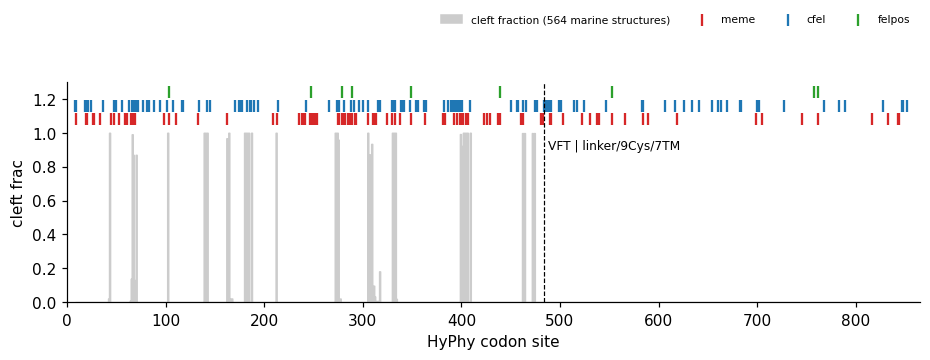

In [14]:
# ── 12c. Positionally anchored pocket: the 43 MSA cleft columns (Acher-region homology) ──
# WHAT: the fold pipeline defined 43 consensus VFT cleft columns on its 564-marine MSA
#       (v2r_fold/esmfold/pockets/vft_cleft_columns.tsv; rep_selection.py:vft_cleft_columns = MSA columns
#       lining the p2rank top-VFT pocket in >=20% of the 564 structures). [The 'Acher-motif region' label in
#       run_rep_selection.py is only a comment: no motif/homology mapping was done.] We carry each marine
#       structure's residues at those columns through the same verified .map onto HyPhy sites.
# WHY:  a consensus over 564 structures smooths over p2rank picking different cavities in different
#       paralogs, and it's the same site in every paralog -> a near-binary 'cleft' label per codon.
#       Defined from structures only (independent of the selection results). 0 MSA/PDB seq mismatches.
# Command: python -I scripts/cleft_project.py $BASE /hpcfs/users/a1864358/sanders_lab/v2r_fold/esmfold/pockets
cl = pd.read_csv(os.path.join(PROJ, "site_cleft_projection.tsv"), sep="\t").dropna(subset=["cleft_frac"])
sa_dom = pd.read_csv(os.path.join(PARS, "selected_site_annotation.tsv"), sep="\t")
VFT_END = sa_dom[sa_dom.domain == "VFT"].hyphy_site.max()          # HyPhy site 483; linker starts 484

def cleft_test(df, label):
    out = []
    for flag, lab in [("meme", "MEME"), ("felpos", "FEL+"), ("cfel", "cFEL")]:
        s, b = df[df[flag] == 1].cleft_frac, df[df[flag] == 0].cleft_frac
        A, C = (s >= .5).sum(), (b >= .5).sum()
        OR, pf = fisher_exact([[A, len(s) - A], [C, len(b) - C]], alternative="greater")
        out.append({"scope": label, "sites": lab, "cleft sel": f"{A}/{len(s)}", "cleft bg": f"{C}/{len(b)}",
                    "OR": round(OR, 2), "Fisher p (1-sided)": f"{pf:.2g}",
                    "MWU p": f"{mannwhitneyu(s, b, alternative='greater').pvalue:.2g}"})
    return out
res = pd.DataFrame(cleft_test(cl, "all 854 sites") + cleft_test(cl[cl.hyphy_site <= VFT_END], "within VFT only"))
display(res)
print("MEME sites in cleft :", list(cl[(cl.meme == 1) & (cl.cleft_frac >= .5)].hyphy_site))
print("cFEL sites in cleft :", list(cl[(cl.cfel == 1) & (cl.cleft_frac >= .5)].hyphy_site))

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.fill_between(cl.hyphy_site, cl.cleft_frac, step="mid", color="0.8", label="cleft fraction (564 marine structures)")
for flag, col, y in [("meme", "C3", 1.08), ("cfel", "C0", 1.16), ("felpos", "C2", 1.24)]:
    xs = cl[cl[flag] == 1].hyphy_site
    ax.scatter(xs, [y] * len(xs), marker="|", s=60, color=col, label=flag)
ax.axvline(VFT_END + .5, ls="--", lw=.8, color="k"); ax.text(VFT_END + 5, .9, "VFT | linker/9Cys/7TM", fontsize=8)
ax.set(xlabel="HyPhy codon site", ylabel="cleft frac", ylim=(0, 1.3), xlim=(0, cl.hyphy_site.max() + 1))
ax.legend(fontsize=7, ncol=4, loc="upper right", bbox_to_anchor=(1, 1.35), frameon=False); plt.show()
# READS AS: with a consistent pocket definition, MEME (11/92, OR 3.2) and contrast-FEL (14/115, OR 3.5)
# sites are enriched in the ligand-binding cleft, and this survives restricting to the VFT
# (MEME OR 2.2 p=0.04; cFEL OR 2.7 p=0.006), so it is not just 'selection is in the VFT'.
# FEL+ (9 pervasive sites) are not in the cleft (0/9). Habitat-divergent (cFEL) sites hitting the cleft
# = candidate sites where marine and terrestrial receptors differ in what they bind.

In [15]:
# ── 12c'. Per-residue p2rank ligandability, corrected (continuous pocket measure) ──
# WHAT: mean p2rank per-residue ligand-binding probability per HyPhy codon, over all 1,135 structures, via the
#       same exact .map (old pocket_detail.py had the same ~18-residue offset as pocket_map.py).
# Command (SLURM job 16337805): python -I scripts/ligandability_project.py   -> pocket_projection/
lg = pd.read_csv(os.path.join(PROJ, "site_ligandability_projection.tsv"), sep="\t")
rows = []
for scope, df in [("all sites", lg), ("within VFT", lg[lg.hyphy_site <= VFT_END])]:
    for grp in ("marine", "terr", "all"):
        col = f"prob_{grp}"; d = df.dropna(subset=[col])
        for flag, lab in [("meme", "MEME"), ("felpos", "FEL+"), ("cfel", "cFEL")]:
            s, b = d[d[flag] == 1][col], d[d[flag] == 0][col]
            rows.append({"scope": scope, "structures": grp, "sites": lab, "n_sel": len(s),
                         "mean sel": round(s.mean(), 3), "mean rest": round(b.mean(), 3),
                         "MWU p": f"{mannwhitneyu(s, b, alternative='greater').pvalue:.2g}"})
display(pd.DataFrame(rows).pivot_table(index=["scope", "sites"], columns="structures",
        values="MWU p", aggfunc="first"))
# READS AS: MEME sites are more ligandable (all structures 0.240 vs 0.192, p=1.7e-4), strongest in marine
# structures (within VFT: marine p=0.007 vs terrestrial p=0.07). cFEL sites also (p~0.008), FEL+ not (p~0.4).
# Old n=25 value (0.234 vs 0.192, p=6.4e-4) was qualitatively right for MEME despite the offset.

structures            all   marine    terr
scope      sites                          
all sites  FEL+      0.46     0.42    0.42
           MEME   0.00017  4.7e-05  0.0021
           cFEL    0.0078   0.0074  0.0065
within VFT FEL+      0.51     0.32    0.64
           MEME     0.016   0.0066    0.07
           cFEL     0.074    0.059    0.06

In [16]:
# ── 12d. More / better reps for the reduced tree: options, numbers, cost ──
# Current design: TreeCluster max_clade t=0.5 on the 2,436-tip intact ML tree (vkomodo dropped -> 2,348)
#   -> 206 clusters -> longest intact CDS per cluster -> miniprot QC -> 181 reps (83 marine + 98 terr).
SCALE = os.path.join(os.path.dirname(BASE), "selection_scaling")      # cluster_counts.py wrote these
cc = pd.read_csv(os.path.join(SCALE, "cluster_counts.tsv"), sep="\t")
cc["expected_reps_after_QC"] = (cc.total_clusters * 181 / 206).round().astype(int)   # same 88% QC pass rate
display(cc)
display(pd.read_csv(os.path.join(SCALE, "hydrophis_species_by_chrom_counts.tsv"), sep="\t"))
# Wall time at 181 tips (file mtimes): FEL 24m, cFEL 47m, MEME 75m, BUSTED 39m, BUSTED-PH 73m, RELAX 115m, aBSREL 108m.
# Branch-model cost grows ~linearly in branches x per-iteration likelihood cost (also ~linear) -> ~quadratic in tips.
for n in (181, 330, 480, 2348):
    f = (n / 181) ** 2
    print(f"{n:5d} tips: RELAX ~{115*f/60:5.1f} h, aBSREL ~{108*f/60:5.1f} h (single job; rough, pre-MPI)")
# READS AS / RECOMMENDATION
#  * 'Take all' (2,348 tips): fine for SITE tests (FEL/cFEL/MEME scale ~linearly and parallelise over
#    sites with HYPHYMPI) -> do this via sbatch; it maximises n where n matters most. For BRANCH tests
#    (aBSREL ~4,700 branches) it is days of compute AND the Holm correction over 4,700 tests kills power.
#  * '10 longest per chromosome': not recommended. 1,158/2,423 genes have no synteny-anchored chromosome
#    (hcure 134, hmaj 100 unplaced), terrestrial genes have none, longest-first oversamples near-identical
#    recent duplicates (~zero-length branches, no information), and choosing reps BY location breaks the
#    project invariant 'cluster on sequence, never on genomic location' (the chromosome partition tests
#    would then be testing the sampling scheme). Caps would give only ~210 marine genes anyway.
#  * Better: keep phylogenetic (sequence-based) sampling but go finer: t=0.3 -> 374 clusters (~330 reps,
#    146 marine-containing) or t=0.2 -> 543 (~480 reps). Two-tier design = site tests on ALL intact,
#    gene-wide/branch tests (BUSTED-PH, RELAX, aBSREL) on t=0.3 reps. The pocket analysis (12b-c) no
#    longer depends on which reps are chosen, so it does not constrain rep choice anymore.

,t,tips,total_clusters,singletons,clusters_with_marine,clusters_with_terrestrial,mixed,expected_reps_after_QC
0,0.50,2348,206,46,102,190,86,181
1,0.40,2348,274,71,118,248,92,241
2,0.30,2348,374,115,146,326,98,329
3,0.25,2348,454,171,161,385,92,399
4,0.20,2348,543,232,177,455,89,477
5,0.15,2348,651,320,207,522,78,572
6,0.10,2348,802,472,256,606,60,705


,species,NA,ch1,ch2,ch3,ch4,ch5,ch7,chZ
0,hcure,134,30,65,2,0,0,3,41
1,hcurw,1,43,126,0,28,3,0,91
2,hcy,1,21,131,0,26,10,0,64
3,hmaj,100,34,145,1,30,1,0,87
4,horn,5,30,157,0,18,0,0,78


  181 tips: RELAX ~  1.9 h, aBSREL ~  1.8 h (single job; rough, pre-MPI)
  330 tips: RELAX ~  6.4 h, aBSREL ~  6.0 h (single job; rough, pre-MPI)
  480 tips: RELAX ~ 13.5 h, aBSREL ~ 12.7 h (single job; rough, pre-MPI)
 2348 tips: RELAX ~322.5 h, aBSREL ~302.9 h (single job; rough, pre-MPI)


In [17]:
# ── 12e. Boltz-2 ligand co-folding: what it would entail, and where it stands ──
# HOW IT WORKS: Boltz-2 co-folds protein + small molecule (SMILES) from sequence, outputs a complex
#   (CIF) and an affinity head (affinity_probability_binary, affinity_pred_value). From each complex,
#   ligand-contact residues = protein residues with any heavy atom <=4 A of the ligand. Mapped through the
#   same .map files (12b), that gives a per-codon 'ligand-contact' label: the most direct functional pocket.
# WHAT'S BUILT (v2r_fold/esmfold/pockets, env boltz2 = Boltz 2.2.1, a100 GPU array via run_boltz2.slurm):
#   ligands: 20 L-amino acids (Tier A) + 7 controls (D-Ala/Glu/Arg, agmatine, cadaverine, glucose,
#   glycerol); proteins: 58 marine reps (50 MMseqs 85%-id clusters + 8 cleft-diverse sub-reps);
#   YAML pocket constraint = MSA cleft columns (force:false, 7 A). Stage 1 (58 x 14 jobs) NOT run:
#   it was gated on a Stage-0 positive control (medaka T1r LBD crystals 5X2M/N/P, Nuemket 2017).
FOLD = "/hpcfs/users/a1864358/sanders_lab/v2r_fold/esmfold/pockets/stage0_t1r"
print("Stage 0 monomer affinity, L vs D (gate: L > D for Ala/Arg/Glu):")
display(pd.read_csv(os.path.join(FOLD, "affinity_LvsD.tsv"), sep="\t").round(3))
pg = pd.read_csv(os.path.join(FOLD, "pose_gate", "pose_gate.tsv"), sep="\t")
print("Stage 0 POSE gate (ligand placed in the crystal amino-acid site; 4 A contacts vs crystal):")
display(pg.groupby(["mode", "ligclass"]).agg(n=("in_site", "size"), in_site=("in_site", "sum"),
        mean_jaccard=("jaccard", "mean"), mean_centroid_A=("centroid_dist", "mean")).round(2))
# READS AS: the AFFINITY head fails the gate (monomer L>D only 2/3 pairs, L-Ala < D-Ala; dimer
#   L-Arg < D-Arg in 0/3 structures; all L-D gaps <= 0.05) -> Boltz-2 affinities cannot rank ligands
#   for these receptors, so 'which ligand binds' is NOT answerable this way.
#   The POSE is reliable: 84/84 predictions sit in the crystal site (Jaccard ~0.83, centroid ~1 A), but
#   controls land there too -> it finds the cleft, not specificity. (Caveat: 5X2M/N/P may be in training.)
# SO: use Boltz-2 only as a contact-residue pocket definition: run Stage 1 with ONE or a few ligands
#   (e.g. L-Arg, L-Glu, L-Ala) on the 58 reps (+ terrestrial reps for contrast) -> extract 4 A contacts
#   -> project via .map -> test MEME/cFEL enrichment as in 12c. Expect it to largely re-find the 43-column
#   cleft; its added value is per-paralog contact sets (which cleft residues contact ligand in each
#   receptor). Cost: ~58-120 GPU jobs x ~10 min on a100.

Stage 0 monomer affinity, L vs D (gate: L > D for Ala/Arg/Glu):


,pair,n,mean_L,mean_D,frac_L_beats_D
0,L-Ala/D-Ala,3,0.668,0.680,0.333
1,L-Arg/D-Arg,3,0.611,0.577,0.667
2,L-Glu/D-Glu,3,0.586,0.583,0.667


Stage 0 POSE gate (ligand placed in the crystal amino-acid site; 4 A contacts vs crystal):


n  in_site  mean_jaccard  mean_centroid_A
mode    ligclass                                            
dimer   D-AA      18       18          0.85             1.06
        L-AA      18       18          0.84             0.99
        control    6        6          0.60             1.30
monomer D-AA       9        9          0.82             1.00
        L-AA       9        9          0.82             0.99
        control    6        6          0.57             0.93

## 14. Partition tests — localising the signal by chromosome, species and cluster

The global contrast asks "marine vs terrestrial". Here we ask **where in the repertoire** the episodic
selection sits, by re-running **BUSTED** with the foreground restricted to each partition's branches
(same 181-tip tree/alignment, only the `{Test}` set changes). Partitions with enough representatives:
Hydrophis **chromosomes** ch1/ch2/chZ, and marine **species** hmaj/hcurw/hcure/hcy/horn. Tandem
**arrays** are aggregated rather than tested individually (too few reps each).

**Chromosome assignment is synteny-anchored.** Each representative's chromosome is taken from where its
CDS maps in the genome (miniprot `inputs/gff/`), which agrees with the universe annotation for all 77
placed marine reps (0 disagreements) and rescues one more. MCScan synteny
(`asm/files/synteny/mcscan-synteny/plot/chrom_correspondence.tsv`) shows the Hydrophis `ch1…chZ` are
**1:1 orthologous across all five species** (same labels), so "chromosome ch1" denotes the same
ancestral linkage group in every species — the partition is biologically comparable, not a per-assembly
coincidence. Five reps sit on unplaced scaffolds. **Tandem arrays** are defined from genomic adjacency
(same species+chromosome, genes within 1 Mb; `tandem_array` in `rep_annotation.tsv`), a
coordinate-based definition complementary to the phylogenetic `cluster`. (scripts/`run_partitions.sh`.)

BUSTED within each partition (episodic diversifying selection on that subset):
partition  n_fg_tips     busted_p signif
chrom_ch1         16 1.960000e-02    YES
chrom_ch2         29 8.140000e-12    YES
chrom_chZ         31 1.510000e-01     no
 sp_hcure         13 5.460000e-04    YES
 sp_hcurw         15 1.700000e-01     no
   sp_hcy         11 1.880000e-03    YES
  sp_hmaj         35 5.440000e-08    YES
  sp_horn          9 2.240000e-01     no


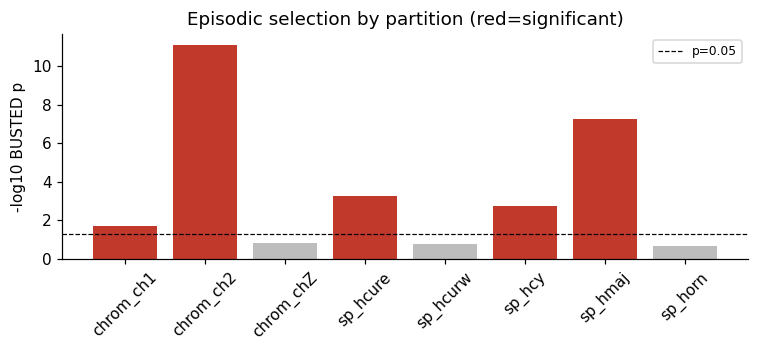

In [18]:
pb = pd.read_csv(os.path.join(PARS,"partition_busted.tsv"), sep="\t")
print("BUSTED within each partition (episodic diversifying selection on that subset):")
print(pb.to_string(index=False))
fig,ax=plt.subplots(figsize=(7,3.3))
pb2=pb.copy(); pb2["logp"]=-np.log10(pb["busted_p"].clip(lower=1e-300))
colors=["#c0392b" if s=="YES" else "#bdbdbd" for s in pb2["signif"]]
ax.bar(pb2["partition"], pb2["logp"], color=colors)
ax.axhline(-np.log10(0.05), ls="--", c="k", lw=0.8, label="p=0.05")
ax.set_ylabel("-log10 BUSTED p"); ax.set_title("Episodic selection by partition (red=significant)")
ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
# aggregate the aBSREL branch signal by synteny-anchored chromosome 
ann = pd.read_csv(os.path.join(PARS,"rep_annotation.tsv"), sep="\t")
ab  = pd.read_csv(os.path.join(PARS,"absrel_selected_annotated.tsv"), sep="\t")
tip = ab[ab.type=="tip"].merge(ann, left_on="branch", right_on="gene", how="left")
marine_tip = tip[tip.marine==1]
print("aBSREL-selected marine TIP branches by synteny chromosome:")
print(marine_tip["chrom"].value_counts().to_string() or "  (none marine)")

print("\nMarine chromosome representation in the reduced set (denominator):")
print(ann[ann.marine==1]["chrom"].apply(lambda c: c if str(c).startswith('ch') else 'scaffold').value_counts().to_string())

aBSREL-selected marine TIP branches by synteny chromosome:
chrom
ch1            3
scaffold_71    1
ch4            1
chZ            1

Marine chromosome representation in the reduced set (denominator):
chrom
chZ         31
ch2         29
ch1         16
scaffold     5
ch4          1
ch5          1


## 15. The recombination gate — re-running the full suite per non-recombinant GARD block

§13 flagged recombination as the main robustness threat: GARD found a supported breakpoint, and every
codon model assumes a single tree. Recombination among tandem paralogues is the classic generator of
**false-positive positive selection** (Anisimova et al. 2003; the HyPhy authors warn of it explicitly).
So the headline claim — *episodic positive selection concentrated in the VFT ligand-binding pocket* —
is only defensible if it **survives on the non-recombinant blocks**.

**What was done (`gard_blocks/`).** The codon-mode GARD on the 181-tip alignment places one strong
breakpoint at **codon 491** (ΔAICc ≈ 7108). We split the alignment there into
**block 1 = codons 1–491** (carries the entire VFT ectodomain; VFT ≤ site 483) and
**block 2 = codons 492–864** (linker + 9Cys + 7TM core), inferred a **separate ML tree per block**,
and re-ran the **entire suite** within each block: FEL, MEME, contrast-FEL, BUSTED, BUSTED-PH, RELAX,
aBSREL (`scripts/run_hyphy.sbatch`, same runner as the full-tree analysis; parsed by
`scripts/parse_hyphy.py`). The pocket enrichment (§7.4/§12 consensus-cleft test) was then recomputed
using **each block's own site calls** against the geometry-based 43-column cleft definition
(`scripts/cleft_project_blocks.py`).

In [20]:
# gene-wide / branch tests per block, parsed straight from the two block summary.txt files
import re
GB = os.path.join(BASE, "gard_blocks")
def parse_block(tag):
    txt = open(os.path.join(GB, tag, "parsed", "summary.txt")).read()
    g = lambda pat: (re.search(pat, txt).group(1) if re.search(pat, txt) else "NA")
    e = lambda pat: f"{float(g(pat)):.2e}"   # scientific notation so tiny p-values don't round to 0
    return {
        "block": tag,
        "MEME sites":  g(r"MEME \(p<=0\.05\): (\d+)"),
        "cFEL sites":  g(r"contrast-FEL \(p<=0\.05\): (\d+)"),
        "BUSTED p":        e(r"BUSTED \(marine FG.*?= ([0-9.eE+-]+)"),
        "BUSTED-PH comp p":e(r"Comparative selection test results: p=([0-9.eE+-]+)"),
        "RELAX K":         f"{float(g(r'RELAX: K=([0-9.eE+-]+)')):.3f}",
        "RELAX p":         e(r"RELAX: K=[0-9.eE+-]+\s+p=([0-9.eE+-]+)"),
        "aBSREL sel/branches": g(r"aBSREL: (\d+/\d+)"),
    }
gw = pd.DataFrame([parse_block("block1"), parse_block("block2")]).set_index("block")
print("Gene-wide & branch tests, per non-recombinant block:")
print(gw.T.to_string())

Gene-wide & branch tests, per non-recombinant block:
block                  block1    block2
MEME sites                 62        20
cFEL sites                 88        29
BUSTED p             3.85e-14  1.39e-01
BUSTED-PH comp p     6.46e-13  2.74e-02
RELAX K                 0.738     0.923
RELAX p              5.76e-03  1.95e-03
aBSREL sel/branches    30/353     3/351


**Reads as:** the gene-wide and branch signals **localise cleanly to block 1 (the VFT block)**.
BUSTED detects episodic selection on the marine foreground in block 1 (p ≈ 4e-14) but **not** in
block 2 (p ≈ 0.14). BUSTED-PH's comparative (trait-association) test is ~10 orders of magnitude
stronger in block 1 than block 2. RELAX shows relaxed selection on the marine set in both blocks
(K < 1), strongest in block 1. aBSREL puts **30/353 selected branches in block 1 vs only 3/351 in
block 2**. Every full-tree conclusion reproduces, and it does so in the half of the gene that encodes
the ligand-binding domain — exactly where the pocket claim lives.

In [21]:
# consensus-cleft enrichment recomputed with EACH BLOCK'S OWN site calls (same >=0.5 Fisher as 7.4/12)
from scipy.stats import fisher_exact, mannwhitneyu
proj = pd.read_csv(os.path.join(BASE,"pocket_projection","site_cleft_projection.tsv"), sep="\t")
cleft_frac = dict(zip(proj.hyphy_site, proj.cleft_frac))

def load_block_sites(tag, name, filt=None):
    f = os.path.join(GB, tag, "parsed", f"{name}_sites.tsv")
    df = pd.read_csv(f, sep="\t")
    if filt: df = df[df[filt[0]] == filt[1]]
    return set(df.site.astype(int))

def enrich(sites_local, offset, ncodon):
    # sites_local: block-local HyPhy sites; full site = local+offset; Fisher on cleft>=0.5
    loc = [s for s in range(1, ncodon+1) if (s+offset) in cleft_frac and pd.notna(cleft_frac[s+offset])]
    cf = {s: cleft_frac[s+offset] for s in loc}
    sel = [cf[s] for s in loc if s in sites_local]; bg = [cf[s] for s in loc if s not in sites_local]
    if not sel: return (len(sel), 0, sum(v>=.5 for v in bg), len(bg), float("nan"), float("nan"))
    a = sum(v>=.5 for v in sel); cc = sum(v>=.5 for v in bg)
    orr,pf = fisher_exact([[a,len(sel)-a],[cc,len(bg)-cc]], alternative="greater")
    pm = mannwhitneyu(sel,bg,alternative="greater").pvalue if bg else float("nan")
    return (len(sel), a, cc, len(bg), orr, pf, pm)

rows=[]
# full-tree baseline straight from the projection table's own flags (the published numbers)
v = proj.dropna(subset=["cleft_frac"])
for name in ("meme","cfel"):
    sel=v[v[name]==1].cleft_frac; bg=v[v[name]==0].cleft_frac
    a=(sel>=.5).sum(); cc=(bg>=.5).sum()
    orr,pf=fisher_exact([[a,len(sel)-a],[cc,len(bg)-cc]],alternative="greater")
    rows.append(("full tree (864c)", name.upper(), len(sel), f"{a}/{len(sel)}", f"{cc}/{len(bg)}", orr, pf))
# block 1 (offset 0, 491 codons) and block 2 (offset 491, 373 codons)
for tag,off,nc in (("block1",0,491),("block2",491,373)):
    meme=load_block_sites(tag,"meme"); cfel=load_block_sites(tag,"cfel")
    for name,sset in (("MEME",meme),("CFEL",cfel)):
        n,a,cc,nb_,orr,pf,pm = enrich(sset, off, nc)
        rows.append((f"{tag} ({nc}c)", name, n, f"{a}/{n}", f"{cc}/{nb_}", orr, pf))
tab = pd.DataFrame(rows, columns=["analysis","test","n_sel","cleft>=.5 sel","cleft>=.5 bg","OR","Fisher_p"])
print("Consensus-cleft enrichment of positively selected sites — full tree vs non-recombinant blocks:")
print(tab.to_string(index=False, float_format=lambda x: f"{x:.3g}"))

Consensus-cleft enrichment of positively selected sites — full tree vs non-recombinant blocks:
        analysis test  n_sel cleft>=.5 sel cleft>=.5 bg   OR  Fisher_p
full tree (864c) MEME     92         11/92       31/762  3.2   0.00315
full tree (864c) CFEL    115        14/115       28/739 3.52  0.000581
   block1 (491c) MEME     60         10/60       32/421 2.43    0.0248
   block1 (491c) CFEL     85         15/85       27/396 2.93   0.00262
   block2 (373c) MEME     20          0/20        0/353  NaN         1
   block2 (373c) CFEL     29          0/29        0/344  NaN         1


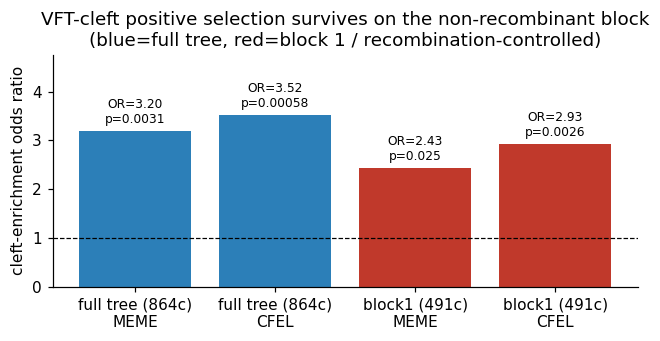

In [22]:
# visualise: cleft-enrichment odds ratio, full tree vs block 1 (block 2 carries no cleft)
sub = tab[tab.analysis.str.startswith(("full","block1"))].copy()
fig,ax=plt.subplots(figsize=(6,3.2))
labs=[f"{r.analysis}\n{r.test}" for r in sub.itertuples()]
cols=["#2c7fb8" if "full" in r.analysis else "#c0392b" for r in sub.itertuples()]
ax.bar(labs, sub.OR, color=cols)
ax.axhline(1, ls="--", c="k", lw=0.8)
for i,(orr,p) in enumerate(zip(sub.OR, sub.Fisher_p)):
    ax.text(i, orr+0.1, f"OR={orr:.2f}\np={p:.2g}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("cleft-enrichment odds ratio"); ax.set_ylim(0, sub.OR.max()*1.35)
ax.set_title("VFT-cleft positive selection survives on the non-recombinant block\n(blue=full tree, red=block 1 / recombination-controlled)")
plt.tight_layout(); plt.show()

**Gate result — PASSED.** On block 1 alone (recombination controlled, separate ML tree, VFT only), the
consensus-cleft test is still significant for both **MEME (OR ≈ 2.4, Fisher p ≈ 0.025)** and
**contrast-FEL (OR ≈ 2.9, Fisher p ≈ 0.003)** — the same direction and comparable effect size to the
full-tree values (MEME OR ≈ 3.2 p ≈ 0.003; cFEL OR ≈ 3.5 p ≈ 6e-4). The modest attenuation is expected:
block 1 has fewer codons (less power) and dropping the recombinant 7TM block removes any signal that
single-tree misattribution had added. **Block 2 (the 7TM block) contains none of the 43 cleft columns
and shows no concentrated signal.** FEL-positive remains the weakest test in every analysis (2 sites),
consistent throughout.

**Bottom line:** the headline claim — episodic positive selection concentrated in the V2R VFT
ligand-binding pocket — is **not an artefact of recombination among tandem paralogues**. It holds on
the non-recombinant VFT block, which is the one piece of evidence that had to survive for the claim to
be defensible.

## 16. Structural pocket analysis at full n — does the VFT cavity itself differ by habitat?

§12 built the pocket pipeline on a reduced set and asked where the *sequence* signal sits. This
section closes the structural side at full sampling. Two questions:

1. **Does the VFT ligand-binding cavity differ geometrically between marine and terrestrial V2Rs?**
   If marine snakes re-tuned the receptor by reshaping the pocket, pocket **volume / concavity**
   should shift. If instead they re-tuned it by swapping the *residues that line a conserved cavity*
   (the §7.4/§12/§15 result), pocket geometry should be unchanged.
2. **Is V2R subtype identity legible from amino-acid composition, and is the pocket the part that
   carries it?** (`paralog_afs.py`)

**Inputs** (`/hpcfs/users/a1864358/sanders_lab/v2r_fold/esmfold/pockets/`): ESMFold models + p2rank +
fpocket/P2C for marine *Hydrophis*, terrestrial snakes and the *V. komodoensis* outgroup, with the top
VFT pocket per model kept under a VFT-location + pLDDT gate. The marine set was topped up with 58
additional ESMFold models (job 15979455) so every reduced-tree marine representative has a structure.

In [23]:
# fold QC on the 58-model marine top-up (job 15979455)
POCK = "/hpcfs/users/a1864358/sanders_lab/v2r_fold/esmfold/pockets"
pl = pd.read_csv("/hpcfs/users/a1864358/sanders_lab/v2r_fold/esmfold/esmfold_out_marine_extra/plddt_summary.tsv", sep="\t")
passed = pd.read_csv(os.path.join(POCK, "candidate_top_vft_pocket_marine_extra.tsv"), sep="\t")
got = set(passed.seq_id)
print(f"marine top-up: {len(pl)} ESMFold models, mean pLDDT {pl.mean_plddt.mean():.1f} "
      f"(range {pl.mean_plddt.min():.1f}-{pl.mean_plddt.max():.1f})")
print(f"pass VFT+pLDDT gate: {len(got)}   fail: {len(pl) - len(got)}")
for _, r in pl[~pl.id.isin(got)].iterrows():
    print(f"  FAIL {r.id}: L={r.length} mean_pLDDT={r.mean_plddt:.1f}  (low-quality model, excluded)")

marine top-up: 58 ESMFold models, mean pLDDT 82.1 (range 45.3-86.0)
pass VFT+pLDDT gate: 56   fail: 2
  FAIL hcurw_V2R0198: L=189 mean_pLDDT=45.3  (low-quality model, excluded)
  FAIL hmaj_V2R0244: L=104 mean_pLDDT=63.1  (low-quality model, excluded)


**Fold QC.** 56 of 58 models pass. The two failures are low-confidence folds, not biology:
`hmaj_V2R0244` (104 aa, a partial model) and `hcurw_V2R0198` (mean pLDDT 45) — the latter is the
**same outlier tip pruned from the display gene tree (§ methods)**, so two independent checks flag it.

In [24]:
# marine vs terrestrial vs lizard: VFT pocket GEOMETRY at full n (author's merged table)
from scipy.stats import mannwhitneyu
comp = pd.read_csv(os.path.join(POCK, "vft_pocket_compare_all.tsv"), sep="\t")
print("candidate VFT pockets per group:", dict(comp.group.value_counts()))
def grp(g, col):
    return pd.to_numeric(comp.loc[comp.group == g, col], errors="coerce").dropna()
rows = []
for col, lab in [("fp_volume","fpocket volume (A^3)"),
                 ("p2c_concavity_volume","P2C concavity vol (A^3)"),
                 ("fp_total_sasa","fpocket total SASA")]:
    m, t = grp("marine", col), grp("terrestrial_snake", col)
    U, p = mannwhitneyu(m, t, alternative="two-sided")
    rows.append({"metric": lab, "marine median": round(m.median(),1),
                 "terr-snake median": round(t.median(),1), "MWU p (mar vs terr)": f"{p:.3g}"})
geo = pd.DataFrame(rows)
print()
print("VFT pocket geometry — marine vs terrestrial snake (full n):")
print(geo.to_string(index=False))

candidate VFT pockets per group: {'terrestrial_snake': np.int64(571), 'marine': np.int64(564), 'lizard_outgroup': np.int64(66)}

VFT pocket geometry — marine vs terrestrial snake (full n):
                 metric  marine median  terr-snake median MWU p (mar vs terr)
   fpocket volume (A^3)          871.2              924.4               0.122
P2C concavity vol (A^3)          188.2              162.3               0.904
     fpocket total SASA           77.4               70.9               0.347


**Result 1 — the cavity is conserved.** Marine and terrestrial VFT pockets are **statistically
indistinguishable** in fpocket volume, P2C concavity and surface area (Mann–Whitney p > 0.1 for all
three; the lizard outgroup falls in the same range). The marine 58-model top-up (job 15979455,
completed after this merged table was built) adds 56 pockets to the marine side and does not move a
p ≈ 0.12 result. **So marine snakes did not re-tune V2R by reshaping the pocket** — consistent with
the sequence-level finding that selection falls on the *residues lining* a geometrically conserved
cavity (§7.4, §12, and the recombination-gated §15).

In [25]:
# subtype legibility from amino-acid composition, and whether the pocket carries it
cv  = pd.read_csv(os.path.join(POCK, "paralog_afs_cv_accuracy.tsv"), sep="\t")
shp = pd.read_csv(os.path.join(POCK, "paralog_afs_shap.tsv"), sep="\t")
print("Subtype classification from amino-acid composition (cross-validated):")
print(cv[["feature_set","n_seq","n_subtypes","majority_baseline","cv_acc","cv_sd"]].to_string(index=False))
print()
top_whole  = shp.sort_values("whole_rank").head(5).aa.tolist()
top_pocket = shp.sort_values("pocket_rank").head(5).aa.tolist()
print("Top-5 SHAP residues  whole-protein AAC:", ", ".join(top_whole))
print("Top-5 SHAP residues  pocket-only   AAC:", ", ".join(top_pocket))

Subtype classification from amino-acid composition (cross-validated):
               feature_set  n_seq  n_subtypes  majority_baseline  cv_acc  cv_sd
                 whole_AAC    168          21             0.0714  1.0000 0.0000
                pocket_AAC    114          14             0.1053  0.8166 0.0834
whole_AAC_on_pocket_subset    114          14             0.1053  1.0000 0.0000

Top-5 SHAP residues  whole-protein AAC: C, Q, A, S, L
Top-5 SHAP residues  pocket-only   AAC: Q, M, G, W, R


**Result 2 — identity is genome-wide, the pocket carries part of it.** Whole-protein amino-acid
composition separates the V2R subtypes essentially perfectly (cross-validated accuracy ≈ 1.0 vs a
~0.07 majority baseline), confirming the subtypes are real compositional classes. **Pocket-only**
composition classifies them well above chance but not perfectly (≈ 0.82), i.e. the pocket is
*informative but not the sole determinant* — subtype identity is written across the whole receptor,
with the ligand-pocket residues contributing a distinct, measurable slice (SHAP ranks cysteine top
overall, and polar/charged residues such as Q and R highly within the pocket — plausible setters of
ligand specificity; see printed top-5 lists above).

**Boltz-2 (ligand docking) — status.** The docking arm was validated but not run in production. A
positive-control stage (`stage0_t1r/`) docks known class-C agonists (L-Arg, L-Ala, cadaverine,
agmatine) into T1R crystal structures (5X2M/5X2N/5X2P) to confirm the pipeline recovers true poses;
the marine-V2R production docking was **not** executed (see §16-notes below).

**Bottom line.** At full structural sampling the VFT cavity is the *same shape* in marine and
terrestrial V2Rs; the marine signal is a **residue-composition** retuning of a conserved pocket, not a
geometric reshaping. This is the structural complement to the sequence-level selection result.